# Cell 1: Imports and upload

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from google.colab import files
uploaded = files.upload()   # choose "Student Depression Dataset.csv"

df = pd.read_csv("Student Depression Dataset.csv")
print(df.shape)
df.head()

Saving Student Depression Dataset.csv to Student Depression Dataset.csv
(27901, 18)


,id,Gender,Age,City,Profession,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Sleep Duration,Dietary Habits,Degree,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,Depression
0,2,Male,33.0,Visakhapatnam,Student,5.0,0.0,8.97,2.0,0.0,5-6 hours,Healthy,B.Pharm,Yes,3.0,1.0,No,1
1,8,Female,24.0,Bangalore,Student,2.0,0.0,5.90,5.0,0.0,5-6 hours,Moderate,BSc,No,3.0,2.0,Yes,0
2,26,Male,31.0,Srinagar,Student,3.0,0.0,7.03,5.0,0.0,Less than 5 hours,Healthy,BA,No,9.0,1.0,Yes,0
3,30,Female,28.0,Varanasi,Student,3.0,0.0,5.59,2.0,0.0,7-8 hours,Moderate,BCA,Yes,4.0,5.0,Yes,1
4,32,Female,25.0,Jaipur,Student,4.0,0.0,8.13,3.0,0.0,5-6 hours,Moderate,M.Tech,Yes,1.0,1.0,No,0


#PART 1: PREPROCESSING
# Cell 2: Inspect the data

In [2]:
df.info()
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicates:", df.duplicated().sum())
print("\nTarget distribution:\n", df["Depression"].value_counts())
df.describe(include="all").T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27901 entries, 0 to 27900
Data columns (total 18 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   id                                     27901 non-null  int64  
 1   Gender                                 27901 non-null  object 
 2   Age                                    27901 non-null  float64
 3   City                                   27901 non-null  object 
 4   Profession                             27901 non-null  object 
 5   Academic Pressure                      27901 non-null  float64
 6   Work Pressure                          27901 non-null  float64
 7   CGPA                                   27901 non-null  float64
 8   Study Satisfaction                     27901 non-null  float64
 9   Job Satisfaction                       27901 non-null  float64
 10  Sleep Duration                         27901 non-null  object 
 11  Di

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,27901.0,NaN,NaN,NaN,70442.149421,40641.175216,2.0,35039.0,70684.0,105818.0,140699.0
Gender,27901,2,Male,15547,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,27901.0,NaN,NaN,NaN,25.8223,4.905687,18.0,21.0,25.0,30.0,59.0
City,27901,52,Kalyan,1570,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Profession,27901,14,Student,27870,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Academic Pressure,27901.0,NaN,NaN,NaN,3.141214,1.381465,0.0,2.0,3.0,4.0,5.0
Work Pressure,27901.0,NaN,NaN,NaN,0.00043,0.043992,0.0,0.0,0.0,0.0,5.0
CGPA,27901.0,NaN,NaN,NaN,7.656104,1.470707,0.0,6.29,7.77,8.92,10.0
Study Satisfaction,27901.0,NaN,NaN,NaN,2.943837,1.361148,0.0,2.0,3.0,4.0,5.0
Job Satisfaction,27901.0,NaN,NaN,NaN,0.000681,0.044394,0.0,0.0,0.0,0.0,4.0


# Cell 3: Clean the data

In [3]:
# Drop duplicates and the id column (no predictive value)
df = df.drop_duplicates()
df = df.drop(columns=["id"])

# Rename the awkward column names
df = df.rename(columns={
    "Have you ever had suicidal thoughts ?": "Suicidal_Thoughts",
    "Family History of Mental Illness": "Family_History",
    "Work/Study Hours": "Work_Study_Hours",
    "Academic Pressure": "Academic_Pressure",
    "Work Pressure": "Work_Pressure",
    "Study Satisfaction": "Study_Satisfaction",
    "Job Satisfaction": "Job_Satisfaction",
    "Sleep Duration": "Sleep_Duration",
    "Dietary Habits": "Dietary_Habits",
    "Financial Stress": "Financial_Stress",
})

# Strip stray whitespace/quotes in text columns
for c in df.select_dtypes(include="object").columns:
    df[c] = df[c].astype(str).str.strip().str.replace("'", "", regex=False)

# Treat "Others" as missing in categorical columns
df = df.replace({"Others": np.nan, "nan": np.nan})

# Financial_Stress may contain "?" in some versions of this dataset
df["Financial_Stress"] = pd.to_numeric(df["Financial_Stress"], errors="coerce")

print(df.isnull().sum())

Gender                 0
Age                    0
City                   0
Profession             0
Academic_Pressure      0
Work_Pressure          0
CGPA                   0
Study_Satisfaction     0
Job_Satisfaction       0
Sleep_Duration        18
Dietary_Habits        12
Degree                35
Suicidal_Thoughts      0
Work_Study_Hours       0
Financial_Stress       3
Family_History         0
Depression             0
dtype: int64


# Cell 4: Handle missing values and outliers

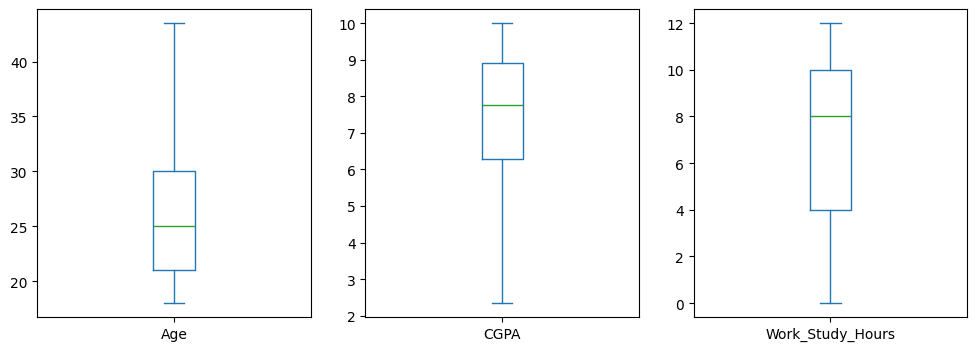

In [4]:
num_cols = df.select_dtypes(include=np.number).columns.drop("Depression")
cat_cols = df.select_dtypes(include="object").columns

# Impute: median for numeric, mode for categorical
for c in num_cols:
    df[c] = df[c].fillna(df[c].median())
for c in cat_cols:
    df[c] = df[c].fillna(df[c].mode()[0])

# Outlier capping (IQR method) on continuous columns
for c in ["Age", "CGPA", "Work_Study_Hours"]:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    df[c] = df[c].clip(q1 - 1.5 * iqr, q3 + 1.5 * iqr)

# Boxplots after capping
df[["Age", "CGPA", "Work_Study_Hours"]].plot(kind="box", subplots=True, layout=(1, 3), figsize=(12, 4))
plt.show()

# Cell 5: Exploratory visuals

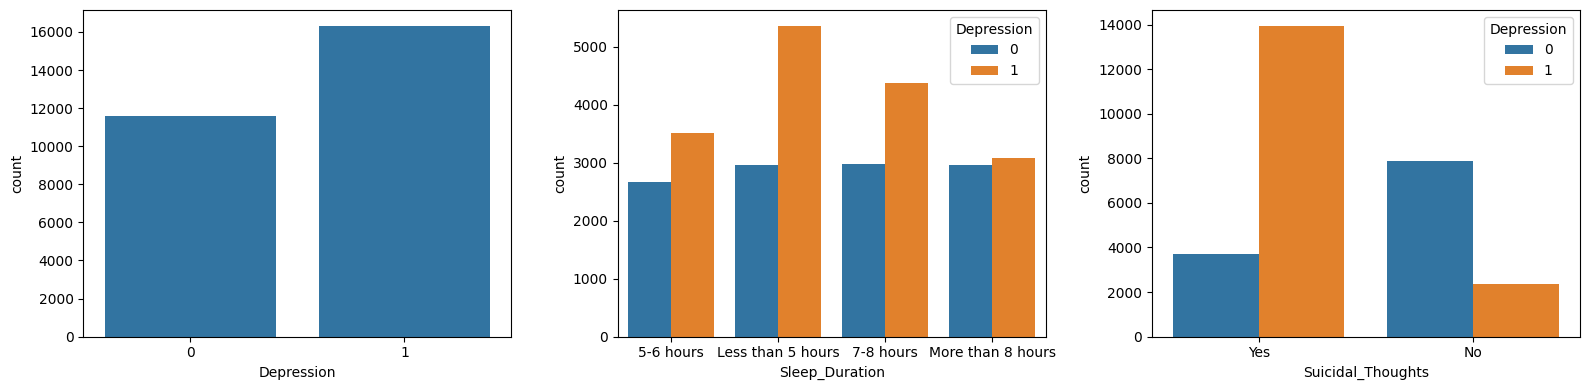

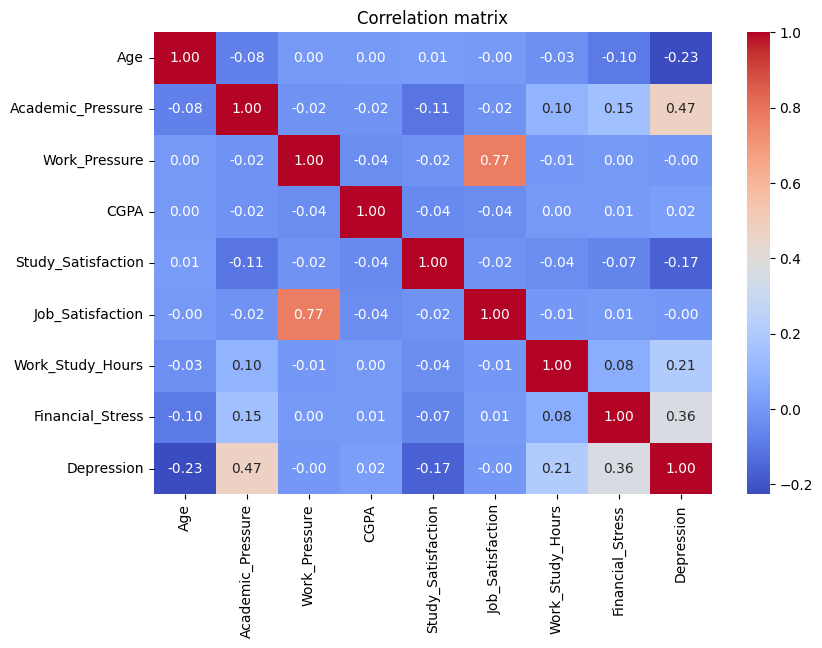

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(x="Depression", data=df, ax=ax[0])
sns.countplot(x="Sleep_Duration", hue="Depression", data=df, ax=ax[1])
sns.countplot(x="Suicidal_Thoughts", hue="Depression", data=df, ax=ax[2])
plt.tight_layout(); plt.show()

plt.figure(figsize=(9, 6))
sns.heatmap(df.select_dtypes(include=np.number).corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation matrix")
plt.show()

# Cell 6: Encoding and scaling

In [6]:
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

df_model = df.copy()

# Drop high-cardinality / near-constant columns
# (City has many values, Profession is almost all "Student")
df_model = df_model.drop(columns=["City", "Profession", "Work_Pressure", "Job_Satisfaction"])

# Binary columns -> 0/1
df_model["Suicidal_Thoughts"] = df_model["Suicidal_Thoughts"].map({"Yes": 1, "No": 0})
df_model["Family_History"] = df_model["Family_History"].map({"Yes": 1, "No": 0})
df_model["Gender"] = df_model["Gender"].map({"Male": 1, "Female": 0})

# Ordinal columns
sleep_map = {"Less than 5 hours": 0, "5-6 hours": 1, "7-8 hours": 2, "More than 8 hours": 3}
diet_map = {"Unhealthy": 0, "Moderate": 1, "Healthy": 2}
df_model["Sleep_Duration"] = df_model["Sleep_Duration"].map(sleep_map)
df_model["Dietary_Habits"] = df_model["Dietary_Habits"].map(diet_map)

# Degree: many values -> label encode
df_model["Degree"] = LabelEncoder().fit_transform(df_model["Degree"])

# Safety net for any unmapped values
df_model = df_model.fillna(df_model.median(numeric_only=True))

X = df_model.drop(columns=["Depression"])
y = df_model["Depression"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print("Train:", X_train.shape, "Test:", X_test.shape)
X.head()

Train: (22320, 12) Test: (5581, 12)


,Gender,Age,Academic_Pressure,CGPA,Study_Satisfaction,Sleep_Duration,Dietary_Habits,Degree,Suicidal_Thoughts,Work_Study_Hours,Financial_Stress,Family_History
0,1,33.0,5.0,8.97,2.0,1,2,3,1,3.0,1.0,0
1,0,24.0,2.0,5.90,5.0,1,1,10,0,3.0,2.0,1
2,1,31.0,3.0,7.03,5.0,0,2,5,0,9.0,1.0,1
3,0,28.0,3.0,5.59,2.0,2,1,7,1,4.0,5.0,1
4,0,25.0,4.0,8.13,3.0,1,1,17,1,1.0,1.0,0


# PART 2: SUPERVISED LEARNING
# Cell 7: Train multiple classifiers

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "Naive Bayes": GaussianNB(),
}

trained, preds, probs = {}, {}, {}
for name, m in models.items():
    m.fit(X_train_s, y_train)
    trained[name] = m
    preds[name] = m.predict(X_test_s)
    probs[name] = m.predict_proba(X_test_s)[:, 1]
    print(f"Trained: {name}")

Trained: Logistic Regression
Trained: Decision Tree
Trained: Random Forest
Trained: Gradient Boosting
Trained: KNN
Trained: Naive Bayes


# Cell 8: Feature importance (Random Forest)

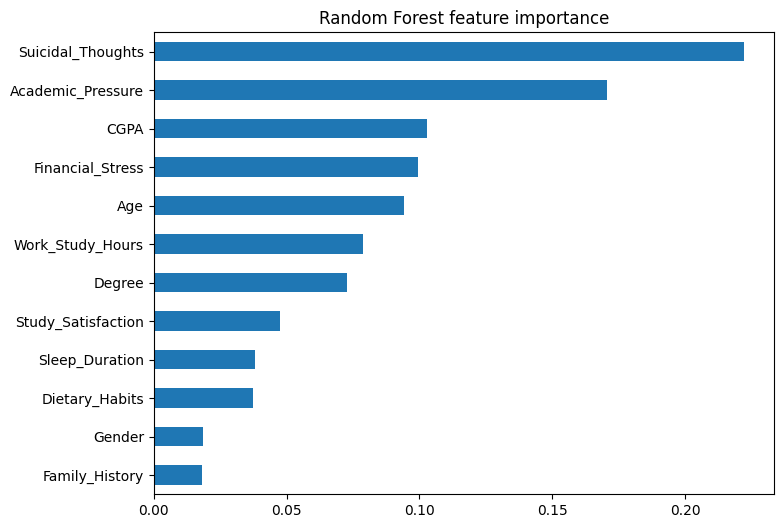

In [8]:
imp = pd.Series(trained["Random Forest"].feature_importances_, index=X.columns).sort_values()
imp.plot(kind="barh", figsize=(8, 6), title="Random Forest feature importance")
plt.show()

# PART 3: UNSUPERVISED LEARNING
# Cell 9: K-Means with elbow and silhouette

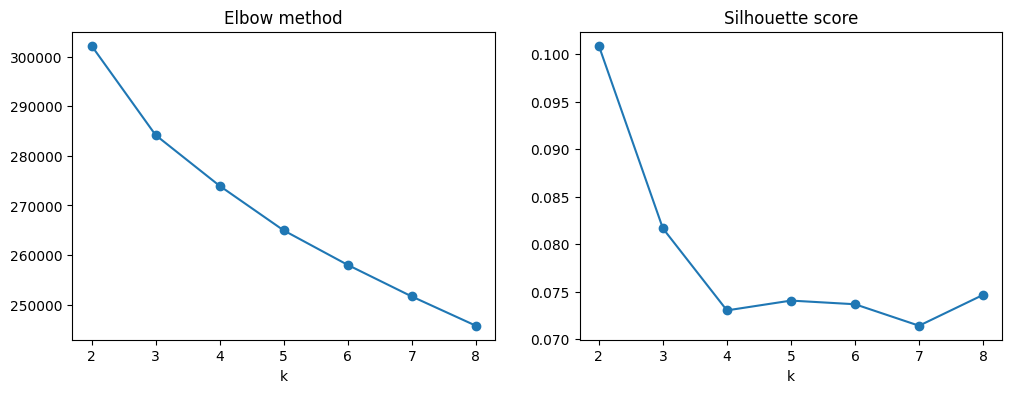

In [9]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X_all_s = scaler.transform(X)

inertia, sil = [], []
K = range(2, 9)
for k in K:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_all_s)
    inertia.append(km.inertia_)
    # Sample for speed on 27k rows
    idx = np.random.RandomState(42).choice(len(X_all_s), 5000, replace=False)
    sil.append(silhouette_score(X_all_s[idx], km.labels_[idx]))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(K, inertia, "o-"); ax[0].set_title("Elbow method"); ax[0].set_xlabel("k")
ax[1].plot(K, sil, "o-"); ax[1].set_title("Silhouette score"); ax[1].set_xlabel("k")
plt.show()

# Cell 10: Final clustering, PCA visualization, cluster profiles

Best k by silhouette: 2


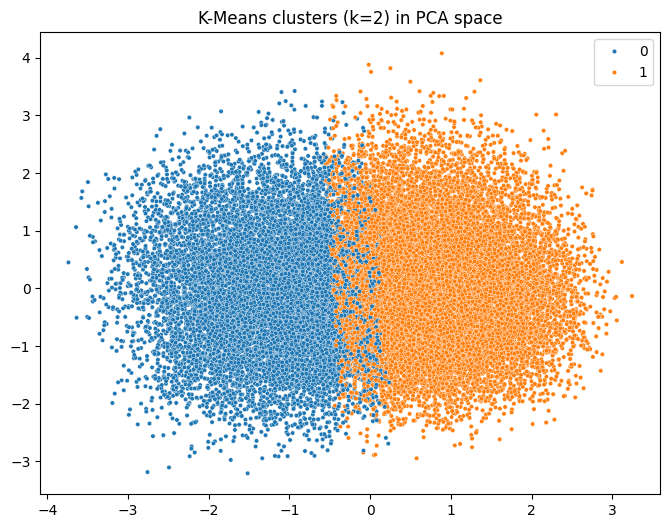

Explained variance: [0.136 0.09 ]

Depression rate per cluster:
Cluster
0    0.187
1    0.863
Name: Depression, dtype: float64

Cluster profiles (means):


,Gender,Age,Academic_Pressure,CGPA,Study_Satisfaction,Sleep_Duration,Dietary_Habits,Degree,Suicidal_Thoughts,Work_Study_Hours,Financial_Stress,Family_History,Depression
Cluster,,,,,,,,,,,,,
0,0.56,27.15,2.35,7.64,3.25,1.52,1.12,11.08,0.20,6.07,2.45,0.45,0.19
1,0.56,24.89,3.70,7.67,2.73,1.31,0.75,10.74,0.93,7.91,3.62,0.51,0.86


In [10]:
from sklearn.decomposition import PCA

best_k = K[int(np.argmax(sil))]
print("Best k by silhouette:", best_k)

km = KMeans(n_clusters=best_k, random_state=42, n_init=10).fit(X_all_s)
df_model["Cluster"] = km.labels_

pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X_all_s)
plt.figure(figsize=(8, 6))
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=km.labels_, palette="tab10", s=10)
plt.title(f"K-Means clusters (k={best_k}) in PCA space")
plt.show()
print("Explained variance:", pca.explained_variance_ratio_.round(3))

# Do clusters align with depression?
print("\nDepression rate per cluster:")
print(df_model.groupby("Cluster")["Depression"].mean().round(3))
print("\nCluster profiles (means):")
df_model.groupby("Cluster").mean().round(2)

# Cell 11: Hierarchical clustering (on a sample)

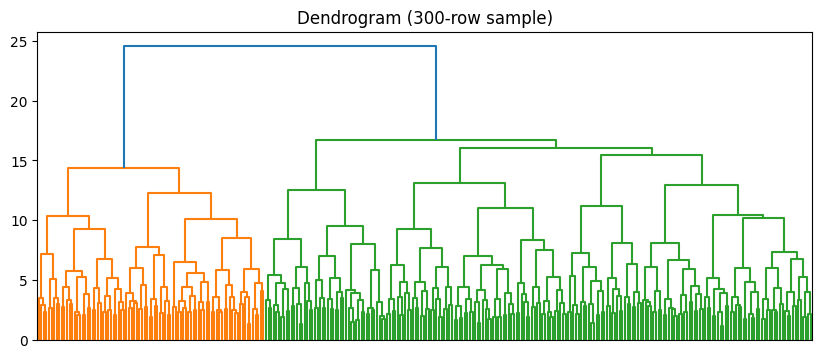

Hierarchical silhouette: 0.088


In [11]:
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering

sample_idx = np.random.RandomState(1).choice(len(X_all_s), 300, replace=False)
Z = linkage(X_all_s[sample_idx], method="ward")
plt.figure(figsize=(10, 4))
dendrogram(Z, no_labels=True)
plt.title("Dendrogram (300-row sample)")
plt.show()

agg = AgglomerativeClustering(n_clusters=best_k).fit(X_all_s[sample_idx])
print("Hierarchical silhouette:", round(silhouette_score(X_all_s[sample_idx], agg.labels_), 3))

# PART 4: FREQUENT PATTERN ANALYSIS
# Cell 12: Build transactions (discretize into items)

In [14]:
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

# mlxtend is usually preinstalled in Colab; if not, run:  !pip install mlxtend
from mlxtend.frequent_patterns import apriori, association_rules

basket = pd.DataFrame(index=df.index)

basket["Age=18-22"] = df["Age"].between(0, 22)
basket["Age=23-27"] = df["Age"].between(23, 27)
basket["Age=28+"] = df["Age"] >= 28

basket["HighAcademicPressure"] = df["Academic_Pressure"] >= 4
basket["LowStudySatisfaction"] = df["Study_Satisfaction"] <= 2
basket["HighFinancialStress"] = df["Financial_Stress"] >= 4
basket["LongStudyHours(8+)"] = df["Work_Study_Hours"] >= 8
basket["LowCGPA(<6)"] = df["CGPA"] < 6

for s in df["Sleep_Duration"].unique():
    basket[f"Sleep={s}"] = df["Sleep_Duration"] == s
for d in df["Dietary_Habits"].unique():
    basket[f"Diet={d}"] = df["Dietary_Habits"] == d

basket["SuicidalThoughts"] = df["Suicidal_Thoughts"] == "Yes"
basket["FamilyHistory"] = df["Family_History"] == "Yes"
basket["Depressed"] = df["Depression"] == 1
basket["Male"] = df["Gender"] == "Male"

basket = basket.astype(bool)
print(basket.shape)
print(basket.mean().round(3).sort_values(ascending=False).head(10))

(27901, 19)
SuicidalThoughts        0.633
Depressed               0.585
Male                    0.557
LongStudyHours(8+)      0.532
FamilyHistory           0.484
HighFinancialStress     0.448
HighAcademicPressure    0.410
Age=28+                 0.406
LowStudySatisfaction    0.405
Diet=Unhealthy          0.370
dtype: float64


# Cell 13: Apriori and association rules

In [15]:
freq = apriori(basket, min_support=0.10, use_colnames=True)
freq["length"] = freq["itemsets"].apply(len)
print("Frequent itemsets:", len(freq))
print(freq.sort_values("support", ascending=False).head(15))

rules = association_rules(freq, metric="confidence", min_threshold=0.6)
rules = rules[rules["lift"] > 1.1]

# Rules that predict depression
dep_rules = rules[rules["consequents"].apply(lambda s: s == frozenset({"Depressed"}))]
dep_rules = dep_rules.sort_values("lift", ascending=False)

cols = ["antecedents", "consequents", "support", "confidence", "lift"]
dep_rules[cols].head(15)

Frequent itemsets: 300
      support                                itemsets  length
15   0.632809                      (SuicidalThoughts)       1
17   0.585499                             (Depressed)       1
18   0.557220                                  (Male)       1
6    0.531630                    (LongStudyHours(8+))       1
131  0.500233           (Depressed, SuicidalThoughts)       2
16   0.483961                         (FamilyHistory)       1
5    0.447654                   (HighFinancialStress)       1
3    0.410415                  (HighAcademicPressure)       1
2    0.405971                               (Age=28+)       1
4    0.404968                  (LowStudySatisfaction)       1
14   0.370202                        (Diet=Unhealthy)       1
93   0.360561  (SuicidalThoughts, LongStudyHours(8+))       2
13   0.355579                         (Diet=Moderate)       1
95   0.354468         (Depressed, LongStudyHours(8+))       2
132  0.352317                (SuicidalThoughts,

,antecedents,consequents,support,confidence,lift
167,"(HighAcademicPressure, SuicidalThoughts, HighF...",(Depressed),0.159027,0.963100,1.644922
177,"(HighAcademicPressure, SuicidalThoughts, Diet=...",(Depressed),0.128669,0.949735,1.622097
171,"(HighAcademicPressure, SuicidalThoughts, LongS...",(Depressed),0.170352,0.944367,1.612928
162,"(HighAcademicPressure, LowStudySatisfaction, S...",(Depressed),0.142647,0.941121,1.607383
210,"(SuicidalThoughts, HighFinancialStress, Diet=U...",(Depressed),0.132576,0.932913,1.593365
165,"(HighAcademicPressure, HighFinancialStress, Lo...",(Depressed),0.110570,0.932306,1.592328
151,"(Age=18-22, SuicidalThoughts, HighFinancialStr...",(Depressed),0.102971,0.931280,1.590576
179,"(HighAcademicPressure, FamilyHistory, Suicidal...",(Depressed),0.145371,0.927298,1.583774
186,"(LowStudySatisfaction, SuicidalThoughts, HighF...",(Depressed),0.134547,0.925542,1.580776
201,"(HighFinancialStress, SuicidalThoughts, LongSt...",(Depressed),0.177449,0.920431,1.572047


# Cell 14: Visualize the rules

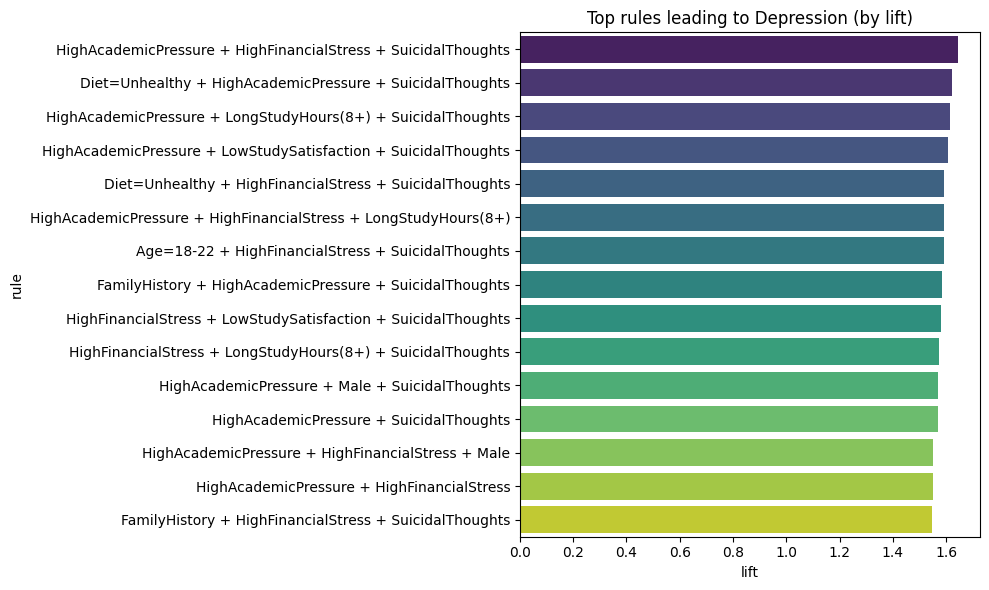

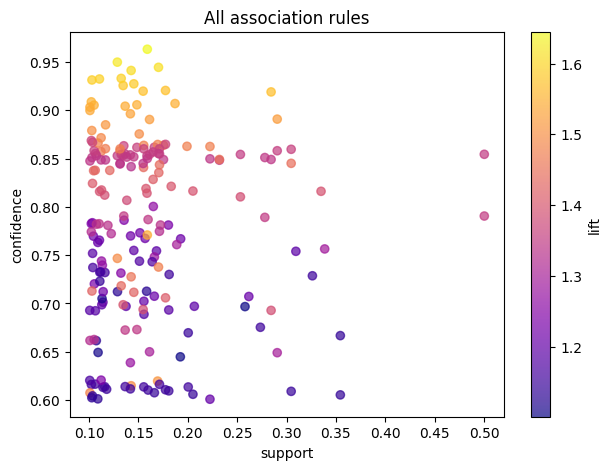

In [16]:
top = dep_rules.head(15).copy()
top["rule"] = top["antecedents"].apply(lambda s: " + ".join(sorted(s)))

plt.figure(figsize=(10, 6))
sns.barplot(data=top, y="rule", x="lift", palette="viridis")
plt.title("Top rules leading to Depression (by lift)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
plt.scatter(rules["support"], rules["confidence"], c=rules["lift"], cmap="plasma", alpha=0.7)
plt.colorbar(label="lift")
plt.xlabel("support"); plt.ylabel("confidence")
plt.title("All association rules")
plt.show()

# PART 5: MODEL EVALUATION
# Cell 15: Metrics comparison table

In [17]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score)

rows = []
for name in models:
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, preds[name]),
        "Precision": precision_score(y_test, preds[name]),
        "Recall": recall_score(y_test, preds[name]),
        "F1": f1_score(y_test, preds[name]),
        "ROC-AUC": roc_auc_score(y_test, probs[name]),
    })

results = pd.DataFrame(rows).set_index("Model").round(4).sort_values("F1", ascending=False)
results

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Gradient Boosting,0.8461,0.8573,0.8843,0.8706,0.9195
Logistic Regression,0.8450,0.8579,0.8813,0.8694,0.9186
Naive Bayes,0.8400,0.8648,0.8614,0.8631,0.9161
Random Forest,0.8353,0.8494,0.8736,0.8614,0.9138
KNN,0.8260,0.8361,0.8742,0.8547,0.8898
Decision Tree,0.8244,0.8383,0.8675,0.8526,0.8964


# Cell 16: Confusion matrices

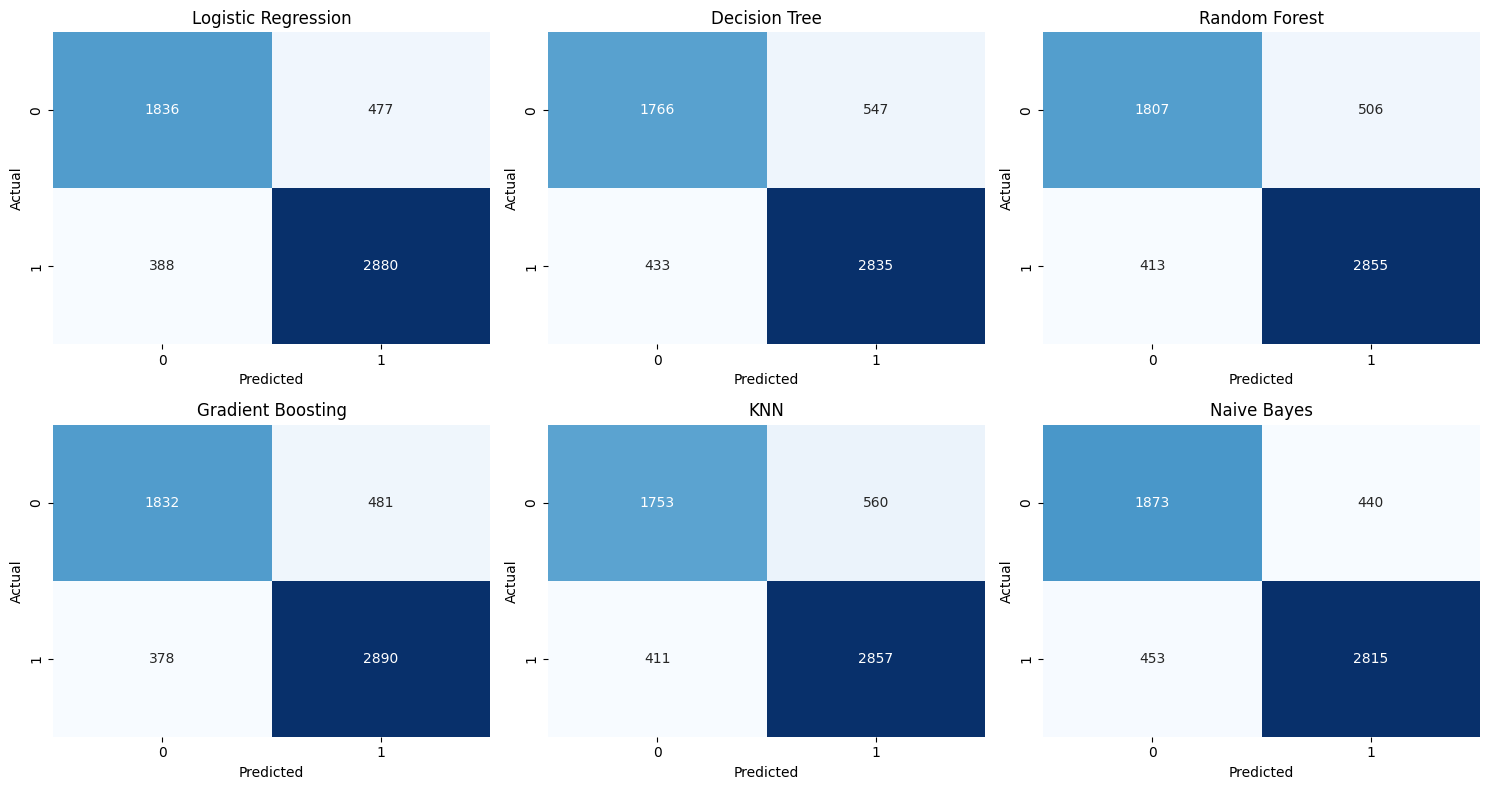

In [18]:
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, name in zip(axes.ravel(), models):
    cm = confusion_matrix(y_test, preds[name])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax, cbar=False)
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

# Cell 17: ROC curves

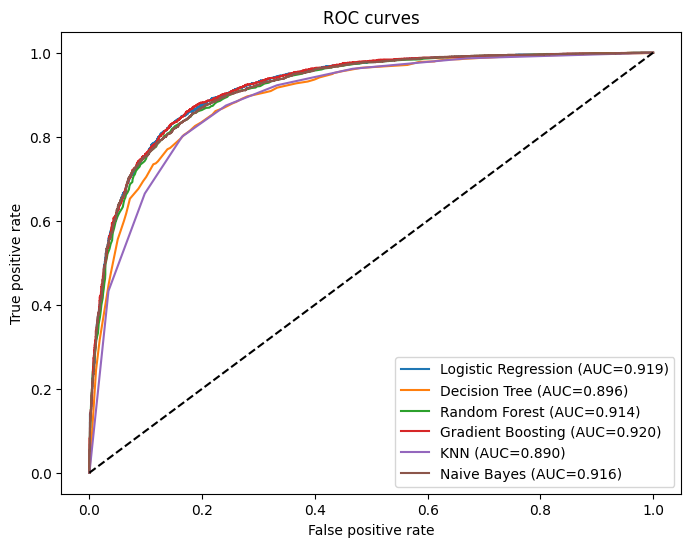

In [19]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(8, 6))
for name in models:
    fpr, tpr, _ = roc_curve(y_test, probs[name])
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, probs[name]):.3f})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curves"); plt.legend()
plt.show()

# Cell 18: Cross-validation and classification report

In [20]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import classification_report

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_rows = []
for name, m in models.items():
    sc = cross_val_score(m, X_train_s, y_train, cv=skf, scoring="f1", n_jobs=-1)
    cv_rows.append({"Model": name, "CV F1 mean": sc.mean(), "CV F1 std": sc.std()})
print(pd.DataFrame(cv_rows).set_index("Model").round(4))

best = results.index[0]
print(f"\nBest model: {best}\n")
print(classification_report(y_test, preds[best], target_names=["No depression", "Depression"]))

                     CV F1 mean  CV F1 std
Model                                     
Logistic Regression      0.8720     0.0012
Decision Tree            0.8576     0.0039
Random Forest            0.8655     0.0009
Gradient Boosting        0.8713     0.0015
KNN                      0.8544     0.0015
Naive Bayes              0.8652     0.0038

Best model: Gradient Boosting

               precision    recall  f1-score   support

No depression       0.83      0.79      0.81      2313
   Depression       0.86      0.88      0.87      3268

     accuracy                           0.85      5581
    macro avg       0.84      0.84      0.84      5581
 weighted avg       0.85      0.85      0.85      5581



# Cell 19: Evaluate clustering

In [21]:
from sklearn.metrics import adjusted_rand_score, davies_bouldin_score

print("K-Means silhouette:", round(silhouette_score(X_all_s[idx], km.labels_[idx]), 4))
print("Davies-Bouldin (lower is better):", round(davies_bouldin_score(X_all_s, km.labels_), 4))
print("Adjusted Rand vs. true Depression label:",
      round(adjusted_rand_score(df_model["Depression"], km.labels_), 4))

K-Means silhouette: 0.1009
Davies-Bouldin (lower is better): 2.9798
Adjusted Rand vs. true Depression label: 0.4679


# Conclusion:
Depression among these students is strongly associated with academic pressure, financial stress, long study hours, low study satisfaction, poor diet and being younger. Supervised models predict it with about 85% accuracy and 0.92 AUC.

Association rules show that high academic pressure combined with high financial stress gives about 91% confidence of depression. Clustering independently separates a low-risk group (19% depressed) from a high-risk group (86% depressed).